NameError: name 'x2' is not defined

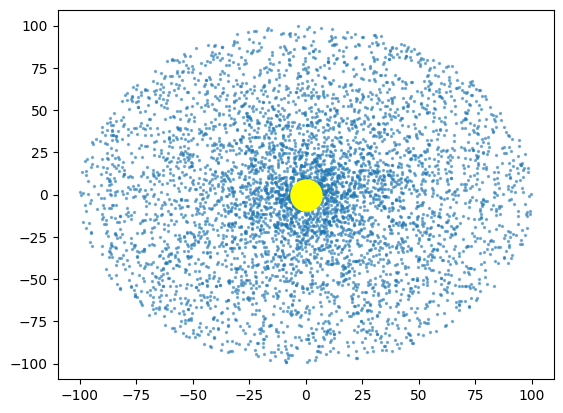

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation

G = 1.0
M_star = 1.0
dt = 0.01

R_inner = 6
R_outer = 100

m_particle = 1e-3

# VISCOSITY
nu_visc0 = 0.0002

# PRESSURE 
cs = 0.01

# SECOND BODY
M2 = 0.01
R2i = 20.0

r2 = R2i
Omega2 = np.sqrt(G * M_star / r2**3)

def bh2_position(t):
    x = r2 * np.cos(Omega2 * t)
    y = r2 * np.sin(Omega2 * t)
    vx = -r2 * Omega2 * np.sin(Omega2 * t)
    vy =  r2 * Omega2 * np.cos(Omega2 * t)
    return x, y, vx, vy

# DISK INITIALIZATION
def initialize_disk(m_particle=m_particle, N=5000):
    r = np.random.uniform(R_inner, R_outer, N)
    theta = np.random.uniform(0, 2*np.pi, N)

    x = r * np.cos(theta)
    y = r * np.sin(theta)

    v = np.sqrt(G * M_star / r)
    vx = -v * np.sin(theta)
    vy =  v * np.cos(theta)

    m = np.ones(N) * m_particle
    return x, y, vx, vy, m

def local_density_proxy(x, y):
    r = np.sqrt(x**2 + y**2)
    return 1.0 / (r + 1e-2)

def pressure_acceleration(x, y):
    r = np.sqrt(x**2 + y**2)
    ax = cs**2 * x / (r**2 + 1e-8)
    ay = cs**2 * y / (r**2 + 1e-8)
    return ax, ay

def bondi_radius(M, v_rel):
    return G * M / (v_rel**2 + cs**2)

def step(x, y, vx, vy, m, t):
    global M2

    x2, y2, vx2, vy2 = bh2_position(t)

    r = np.sqrt(x**2 + y**2)
    ax = -G * M_star * x / (r**3 + 1e-8)
    ay = -G * M_star * y / (r**3 + 1e-8)

    dx2 = x - x2
    dy2 = y - y2
    r2p = np.sqrt(dx2**2 + dy2**2) + 1e-8

    ax += -G * M2 * dx2 / r2p**3
    ay += -G * M2 * dy2 / r2p**3

    ax_p, ay_p = pressure_acceleration(x, y)
    ax += ax_p
    ay += ay_p

    rho = local_density_proxy(x, y)
    rho_mean = np.mean(rho)
    nu_local = nu_visc0 * (rho / (rho_mean + 1e-12))

    ax -= nu_local * vx
    ay -= nu_local * vy

    vx += ax * dt
    vy += ay * dt
    x += vx * dt
    y += vy * dt

    v_rel = np.sqrt((vx - vx2)**2 + (vy - vy2)**2)
    R_acc = bondi_radius(M2, np.mean(v_rel))

    accreted = r2p < R_acc
    if np.any(accreted):
        dm = np.sum(m[accreted])
        M2 += dm
        m[accreted] *= 1e-6

    return x, y, vx, vy, m

# INITIAL STATE
x, y, vx, vy, m = initialize_disk(m_particle=m_particle, N=5000)

# FIGURE
fig, ax = plt.subplots()
scat = ax.scatter(x, y, s=2, alpha=0.5)
star = ax.scatter([0], [0], c='yellow', s=(M_star * 500)//1)
bh = ax.scatter([], [], c='red')

ax.set_xlim(-R_outer, R_outer)
ax.set_ylim(-R_outer, R_outer)
ax.set_aspect('equal')
n=0

# ANIMATION UPDATE
def update(frame):
    global x, y, vx, vy, m, n

    steps_per_frame = 1000  # controls temporal resolution

    for _ in range(steps_per_frame):
        t = frame * dt
        x, y, vx, vy, m = step(x, y, vx, vy, m, t)

    x2, y2, _, _ = bh2_position(frame * dt)

    scat.set_offsets(np.column_stack((x, y)))
    bh.set_offsets([[x2, y2]])
    bh.set_sizes([(M2 * 500)//1])

    ax.set_title(f"frame {frame}, M2={M2:.3f}")
    n = n+1
    print(n)

    return scat, bh

# CREATE ANIMATION
anim = FuncAnimation(fig, update, frames=500, interval=30, blit=False)

# SAVE
anim.save("disk_simulation.mp4", fps=30, dpi=200)

# plt.show()

print("Final M2:", M2)